In [23]:
import pandas as pd

df=pd.read_csv('data/student_performance_clean.csv')
df.drop(columns=['Unnamed: 0.1','Unnamed: 0'],inplace=True)
df

C:\Users\saura\AppData\Local\Temp\ipykernel_3348\4001794042.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Unnamed: 0.1','Unnamed: 0'],inplace=True)


,student_id,gender,study_hours,attendance,previous_score,sleep_hours,internet_access,final_score,pass_status
0,STU0001,Male,0.0,48.7,47.4,7.9,Yes,52.3,0
1,STU0002,Male,4.1,58.5,77.5,6.4,No,62.5,1
2,STU0003,Male,3.9,91.1,54.5,4.3,No,61.4,1
3,STU0004,Female,5.9,64.8,47.5,5.9,No,67.8,1
4,STU0005,Male,6.1,71.0,77.6,7.1,Yes,77.8,1
...,...,...,...,...,...,...,...,...,...
965,STU0966,Female,4.5,86.4,58.9,6.3,Yes,58.2,0
966,STU0967,Female,4.7,61.0,49.0,8.7,No,67.6,1
967,STU0968,Female,4.8,76.1,43.3,6.1,Yes,67.3,1
968,STU0969,Male,5.4,62.0,45.9,7.0,No,75.4,1


In [24]:
X=df[['attendance']]
Y=df['final_score']

X

,attendance
0,48.7
1,58.5
2,91.1
3,64.8
4,71.0
...,...
965,86.4
966,61.0
967,76.1
968,62.0


In [25]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [26]:
poly=PolynomialFeatures(degree=2)

x_poly=poly.fit_transform(X)

x_poly


array([[1.00000e+00, 4.87000e+01, 2.37169e+03],
       [1.00000e+00, 5.85000e+01, 3.42225e+03],
       [1.00000e+00, 9.11000e+01, 8.29921e+03],
       ...,
       [1.00000e+00, 7.61000e+01, 5.79121e+03],
       [1.00000e+00, 6.20000e+01, 3.84400e+03],
       [1.00000e+00, 8.44000e+01, 7.12336e+03]], shape=(970, 3))

In [27]:
model=LinearRegression()
model.fit(x_poly,Y)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0. , 0.19,-0. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,57.11
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[67373.88, 116.31, 0. ]"


In [28]:
y_pred=model.predict(x_poly)

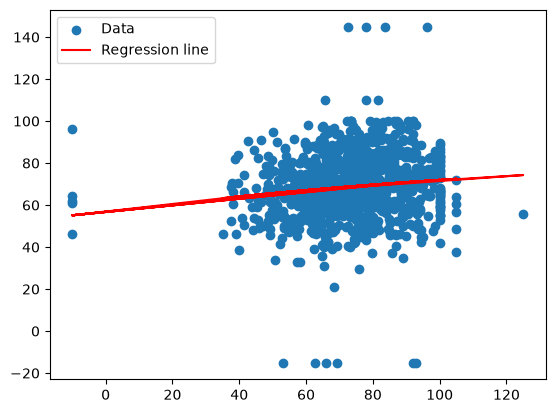

In [29]:
import matplotlib.pyplot as plt

plt.scatter(X,Y,label='Data')
plt.plot(X,y_pred,label='Regression line',c='red')
plt.legend()
plt.show()

